# Building Energy Efficiency - Regression Project
## Notebook 2: Algorithm Selection -> Training -> Evaluation -> Hyperparameter Tuning

**Covers ML process steps 4, 5 and 6.** The **test set is not used anywhere in this notebook**. It stays locked until Notebook 3 so that the final score is honest.

> **Reminder from Notebook 1:** we split the 768 buildings into *train* (70%, the models learn from it), *validation* (15%, we compare and tune on it) and *test* (15%, the final exam). We also found that the data is a **designed grid of only 12 building shapes**, so we add an extra "unseen shapes" stress test below.

In [1]:
import os, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import optuna

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import (KFold, GridSearchCV, RandomizedSearchCV, cross_val_score,
                                     cross_val_predict, LeaveOneGroupOut)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50, "display.width", 220)

SEED = 42
NJ = os.cpu_count()
FIG, MODELS = Path("figures"), Path("models")
FIG.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)
HEAT, COOL = "#EC4259", "#2A7CBD"
TARGET_R2, TARGET_RMSE = 0.95, 2.0                     # success criteria from Notebook 1
COLORS = {"heating_load": HEAT, "cooling_load": COOL}

def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

# ---- load the splits created in Notebook 1 (train and validation only!) ----
S = Path("data/splits")
train, val = pd.read_csv(S / "train.csv"), pd.read_csv(S / "val.csv")
groups_cfg = json.load(open(S / "feature_groups.json"))
FEATS = groups_cfg["numeric"] + groups_cfg["nominal"]
TARGETS = groups_cfg["targets"]
Xtr, Xva, ytr, yva = train[FEATS], val[FEATS], train[TARGETS], val[TARGETS]
print("train:", Xtr.shape, "| validation:", Xva.shape, "| targets:", TARGETS)

def make_pipe(estimator):
    """Preprocessing + model in ONE object, so the scaler/encoder are always fitted on training data only."""
    pre = ColumnTransformer([("num", StandardScaler(), groups_cfg["numeric"]),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), groups_cfg["nominal"])])
    return Pipeline([("prep", pre), ("model", estimator)])

def rmse(y, p): return float(np.sqrt(mean_squared_error(y, p)))

def evaluate(pipe, X, y):
    p = pipe.predict(X)
    return {"MAE": mean_absolute_error(y, p), "MSE": mean_squared_error(y, p), "RMSE": rmse(y, p), "R2": r2_score(y, p)}

/usr/local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train: (537, 11) | validation: (115, 11) | targets: ['heating_load', 'cooling_load']


---
# Step 4 - Algorithm Selection

An **algorithm** is a recipe for learning from data; a **model** is the result after the recipe has studied the training data. No algorithm is best for every problem, so we try one or more from each **family** and let the validation set decide. We weigh **accuracy**, **interpretability** (can a human see why?) and **computational cost**.

| Algorithm | Idea in plain words | Strengths | Watch out for |
|---|---|---|---|
| **Linear Regression** | Draws the best straight-line (flat plane) fit: load = weight1 x input1 + weight2 x input2 + ... | Fast, very easy to explain, great baseline | Cannot bend; unstable when inputs overlap (our multicollinearity) |
| **Ridge / Lasso** | Linear regression with a *penalty* on big weights (Ridge shrinks them, Lasso can push some to exactly 0) | Stable even when inputs overlap | Still a straight line |
| **Polynomial + Ridge** | First adds squared and multiplied versions of the inputs, then fits a penalised line | Can bend and capture interactions, still fairly interpretable | Can wiggle wildly outside the data |
| **k-Nearest Neighbours** | Predicts the average of the *k* most similar training buildings | Simple, no training | Needs scaling; slow with lots of data |
| **Decision Tree** | A flowchart of yes/no questions that ends in a number | Easy to read | One tree **memorises** the training data (overfits) |
| **Random Forest** | Hundreds of different trees, predictions averaged | Accurate, robust, little tuning | Harder to interpret; cannot predict outside the range it has seen |
| **Gradient Boosting / XGBoost** | Trees built one after another, each correcting the previous trees' mistakes | Often the most accurate on tables like ours | Many settings; can overfit |
| **SVR (RBF)** | Fits a smooth curve inside a tolerance "tube" | Good on small, smooth data | Needs scaling; hard to interpret |
| **Neural network (MLP)** | Layers of small connected units that learn combinations of inputs | Very flexible | Needs care and data; a black box |

### The baseline
A **baseline** is the simplest possible predictor: **always predict the average load**. Any real model must beat it (its R² is about 0 by definition).

### Hyperparameters vs. parameters
* **Parameters** are numbers the model *learns* (e.g. a weight in a linear model).
* **Hyperparameters** are *settings we choose before training* (e.g. how many trees, how strong the penalty). Tuning them is Step 6.

---
# Step 5 - Model Development and Training

### 5.1 Define the candidates
Some models (k-NN, SVR, the neural network) work much better when the **target** is also on a standard scale, so for those we wrap the model in a `TransformedTargetRegressor`, which scales the target for training and converts predictions back to normal load units automatically.

In [2]:
def scaled_target(est):
    return TransformedTargetRegressor(regressor=est, transformer=StandardScaler())

def zoo():
    return {
        "Baseline (predict the mean)": DummyRegressor(strategy="mean"),
        "Linear Regression": LinearRegression(),
        "Ridge": Ridge(alpha=1.0),
        "Lasso": Lasso(alpha=0.01, max_iter=20000),
        "Polynomial (deg 2) + Ridge": Pipeline([("poly", PolynomialFeatures(2, include_bias=False)), ("ridge", Ridge(alpha=1.0))]),
        "k-Nearest Neighbours": KNeighborsRegressor(n_neighbors=5),
        "Decision Tree": DecisionTreeRegressor(random_state=SEED),
        "Random Forest": RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=NJ),
        "Gradient Boosting": GradientBoostingRegressor(random_state=SEED),
        "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=4, tree_method="hist", random_state=SEED, n_jobs=NJ),
        "SVR (RBF)": scaled_target(SVR(C=10.0)),
        "Neural Net (MLP)": scaled_target(MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=3000, random_state=SEED)),
    }
print(len(zoo()), "candidate models defined")

12 candidate models defined


### 5.2 Train every candidate and compare on the validation set
We train on the **training** set and score on **both** training and validation data. A big gap (great on training, worse on validation) signals **overfitting**. We do this separately for the **heating** and the **cooling** target.

In [3]:
rows = []
for t in TARGETS:
    for name, est in zoo().items():
        t0 = time.time()
        pipe = make_pipe(est).fit(Xtr, ytr[t])
        sec = time.time() - t0
        tr, va = evaluate(pipe, Xtr, ytr[t]), evaluate(pipe, Xva, yva[t])
        rows.append({"target": t, "model": name, "train_R2": tr["R2"], "val_MAE": va["MAE"], "val_RMSE": va["RMSE"],
                     "val_R2": va["R2"], "train_RMSE": tr["RMSE"], "seconds": sec})
res = pd.DataFrame(rows)
res["overfit_gap_RMSE"] = res["val_RMSE"] - res["train_RMSE"]
show = ["model", "train_RMSE", "val_MAE", "val_RMSE", "val_R2", "overfit_gap_RMSE", "seconds"]
for t in TARGETS:
    print(f"\n=== Target: {t} (validation set; sorted by RMSE, lower is better) ===")
    display(res[res.target == t][show].sort_values("val_RMSE").round(3).reset_index(drop=True))


=== Target: heating_load (validation set; sorted by RMSE, lower is better) ===


,model,train_RMSE,val_MAE,val_RMSE,val_R2,overfit_gap_RMSE,seconds
0,XGBoost,0.188,0.278,0.441,0.998,0.253,8.619
1,Gradient Boosting,0.391,0.380,0.563,0.997,0.171,0.110
2,Random Forest,0.215,0.394,0.638,0.996,0.423,0.660
3,Decision Tree,0.001,0.449,0.845,0.993,0.844,0.016
4,SVR (RBF),0.901,0.977,1.111,0.988,0.210,0.059
5,Neural Net (MLP),0.728,0.901,1.141,0.987,0.413,0.329
6,k-Nearest Neighbours,1.407,1.008,1.505,0.978,0.098,0.012
7,Polynomial (deg 2) + Ridge,1.352,1.106,1.511,0.977,0.159,0.050
8,Linear Regression,1.903,1.448,1.985,0.961,0.082,0.016
9,Lasso,2.531,1.818,2.678,0.929,0.147,0.021



=== Target: cooling_load (validation set; sorted by RMSE, lower is better) ===


,model,train_RMSE,val_MAE,val_RMSE,val_R2,overfit_gap_RMSE,seconds
0,XGBoost,0.501,0.830,1.330,0.980,0.829,12.541
1,Neural Net (MLP),0.850,1.201,1.584,0.972,0.734,0.337
2,Gradient Boosting,1.340,1.043,1.612,0.971,0.272,0.133
3,SVR (RBF),1.149,1.494,1.923,0.958,0.775,0.047
4,Random Forest,0.697,1.243,2.052,0.953,1.355,0.615
5,k-Nearest Neighbours,1.676,1.434,2.123,0.949,0.447,0.025
6,Polynomial (deg 2) + Ridge,1.939,1.758,2.235,0.944,0.296,0.017
7,Decision Tree,0.000,1.410,2.533,0.928,2.533,0.013
8,Linear Regression,2.598,1.964,2.664,0.920,0.065,0.013
9,Lasso,2.995,2.133,3.134,0.889,0.138,0.019


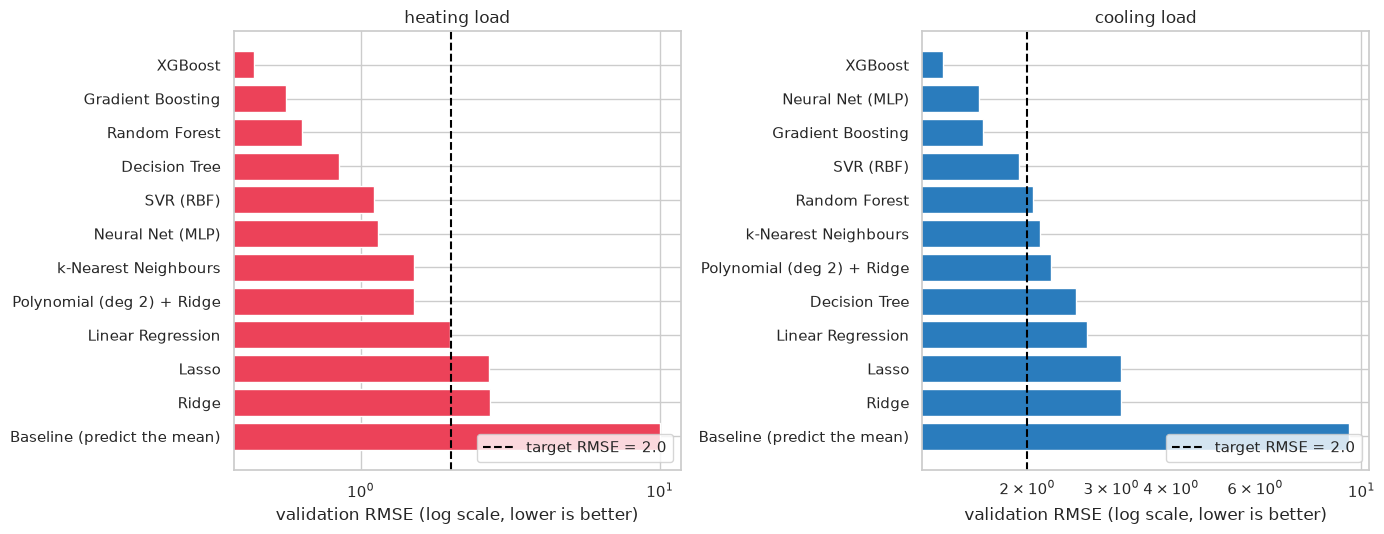

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=False)
for ax, t in zip(axes, TARGETS):
    d = res[res.target == t].sort_values("val_RMSE", ascending=False)
    ax.barh(d["model"], d["val_RMSE"], color=COLORS[t])
    ax.axvline(TARGET_RMSE, color="black", ls="--", label=f"target RMSE = {TARGET_RMSE}")
    ax.set_xscale("log"); ax.set_xlabel("validation RMSE (log scale, lower is better)")
    ax.set_title(t.replace("_", " ")); ax.legend(loc="lower right")
save("05_model_comparison_rmse")
plt.show()

### What the comparison shows (validation set, known shapes)
* **The baseline** (always the average) has an RMSE of about 10.0 (heating) and 9.4 (cooling) and an R² of 0, which confirms there is a lot to explain.
* **Tree-based boosting is best.** Default XGBoost reaches an RMSE of **0.44** for heating (R² 0.998) and **1.33** for cooling (R² 0.980), already inside our target of 2.0.
* **Straight lines cannot bend enough.** Plain Linear Regression has an RMSE of 1.99 (heating) and 2.66 (cooling), so it just misses or fails the target (cooling R² is only 0.920). Ridge and Lasso are *worse* (2.7 and 3.1), because their penalty shrinks the weights and the data does not need shrinking, only bending.
* **Polynomial + Ridge** sits in between (1.51 and 2.24): it can bend, but a degree-2 curve is not flexible enough.
* **Overfitting is visible in the single Decision Tree:** it memorises the training data (training RMSE 0.001 for heating and 0.000 for cooling) but errs by 0.85 and 2.53 on validation. A Random Forest averages many trees and shrinks that gap (0.42 and 1.36).

### 5.3 Underfitting and overfitting
* **Underfitting:** the model is too simple and does badly on *both* training and validation data.
* **Overfitting:** the model is too complex; it is excellent on the training data but worse on new data (it memorised instead of learning).

A **decision tree** shows this clearly: the deeper it may grow, the more it can memorise. We plot training vs. validation error as the allowed depth grows (heating target).

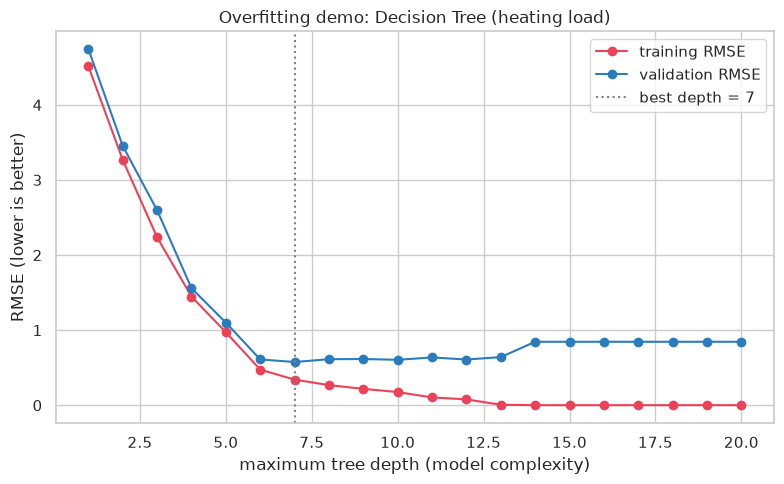

depth 1: train 4.51 / val 4.74 | best depth 7: val 0.58 | depth 20: train 0.00 / val 0.85


In [5]:
pre = make_pipe(None).named_steps["prep"].fit(Xtr)
Zt, Zv = pre.transform(Xtr), pre.transform(Xva)
depths = list(range(1, 21)); tr_e, va_e = [], []
for d in depths:
    tree = DecisionTreeRegressor(max_depth=d, random_state=SEED).fit(Zt, ytr["heating_load"])
    tr_e.append(rmse(ytr["heating_load"], tree.predict(Zt))); va_e.append(rmse(yva["heating_load"], tree.predict(Zv)))
best_d = depths[int(np.argmin(va_e))]
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(depths, tr_e, "o-", color=HEAT, label="training RMSE"); ax.plot(depths, va_e, "o-", color=COOL, label="validation RMSE")
ax.axvline(best_d, color="grey", ls=":", label=f"best depth = {best_d}")
ax.set_xlabel("maximum tree depth (model complexity)"); ax.set_ylabel("RMSE (lower is better)")
ax.set_title("Overfitting demo: Decision Tree (heating load)"); ax.legend()
save("06_overfitting_tree_depth")
plt.show()
print(f"depth 1: train {tr_e[0]:.2f} / val {va_e[0]:.2f} | best depth {best_d}: val {min(va_e):.2f} | depth 20: train {tr_e[-1]:.2f} / val {va_e[-1]:.2f}")

### 5.4 Does more data help? A learning curve
A **learning curve** shows how the validation error changes as the models see more training buildings. If the curve is still falling steeply at the right edge, collecting more data would help; if it is flat, the model has learned what it can.

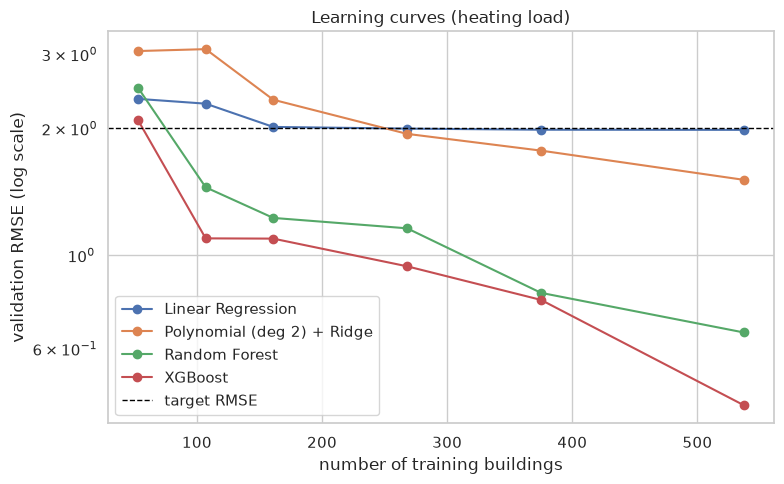

model,Linear Regression,Polynomial (deg 2) + Ridge,Random Forest,XGBoost
training buildings,,,,
53,2.35,3.05,2.50,2.09
107,2.29,3.09,1.45,1.10
161,2.02,2.34,1.23,1.10
268,2.00,1.94,1.16,0.94
375,1.99,1.77,0.81,0.78
537,1.99,1.51,0.66,0.44


In [6]:
fracs = [0.1, 0.2, 0.3, 0.5, 0.7, 1.0]
lc_models = ["Linear Regression", "Polynomial (deg 2) + Ridge", "Random Forest", "XGBoost"]
rng = np.random.default_rng(SEED)
order = rng.permutation(len(Xtr))
lc = []
for name in lc_models:
    for f in fracs:
        n = int(len(Xtr) * f); idx = order[:n]
        pipe = make_pipe(zoo()[name]).fit(Xtr.iloc[idx], ytr["heating_load"].iloc[idx])
        lc.append({"model": name, "training buildings": n, "val RMSE": rmse(yva["heating_load"], pipe.predict(Xva))})
lc = pd.DataFrame(lc)
fig, ax = plt.subplots(figsize=(8, 5))
for name, g in lc.groupby("model", sort=False):
    ax.plot(g["training buildings"], g["val RMSE"], "o-", label=name)
ax.axhline(TARGET_RMSE, color="black", ls="--", lw=1, label="target RMSE")
ax.set_yscale("log"); ax.set_xlabel("number of training buildings"); ax.set_ylabel("validation RMSE (log scale)")
ax.set_title("Learning curves (heating load)"); ax.legend()
save("07_learning_curve")
plt.show()
lc.pivot(index="training buildings", columns="model", values="val RMSE").round(2)

**Reading the curves.** The depth plot above shows the classic overfitting picture: the best tree depth is **7** (validation RMSE 0.58); a tree allowed to grow to depth 20 scores 0.00 on the training data but 0.85 on validation.

In the learning curves, XGBoost's error falls from **2.09** (with 53 training buildings) to **0.44** (537) and is **still falling** at the right edge: more (and especially more *varied*) training buildings would improve it further. Linear Regression is flat at about 2.0 after roughly 160 buildings: a straight line cannot use extra data because its limit is its shape, not the amount of data.

### 5.5 Stress test: predicting shapes the model has never seen
In Notebook 1 we found that the data contains only **12 distinct building shapes**, and our random split puts every shape in the training set. The validation score therefore measures "known shape, new orientation/windows" - the **easy** case.

An architect with a brand-new design needs the **hard** case: a shape that is not in the training data. We simulate this with **leave-one-shape-out** cross-validation: train on 11 shapes, predict the 12th, repeat for each shape, and pool all the predictions. We use training + validation buildings only (the test set stays locked).

Some models can only predict values *inside* the range they have seen (trees and forests); others extrapolate along a trend (linear models). This test shows which behaviour helps.

In [7]:
tv = pd.concat([train, val], ignore_index=True)
Xtv, ytv, gtv = tv[FEATS], tv[TARGETS], tv["shape_id"]

def logo_oof(make_est, target):
    """Leave-one-shape-out predictions for every building (each shape predicted by a model that never saw it)."""
    oof = np.zeros(len(tv))
    for tr_i, te_i in LeaveOneGroupOut().split(Xtv, ytv[target], gtv):
        pipe = make_pipe(make_est()).fit(Xtv.iloc[tr_i], ytv[target].iloc[tr_i])
        oof[te_i] = pipe.predict(Xtv.iloc[te_i])
    return oof

t0 = time.time()
stress, oof_store = [], {}
for t in TARGETS:
    for name, mk in zoo().items():
        oof = logo_oof(lambda mk=mk: clone(mk), t)
        oof_store[(t, name)] = oof
        stress.append({"target": t, "model": name, "unseen_shape_RMSE": rmse(ytv[t], oof), "unseen_shape_R2": r2_score(ytv[t], oof)})
stress = pd.DataFrame(stress)
print(f"finished in {time.time() - t0:.0f} s")
cmp_stress = res.merge(stress, on=["target", "model"])[["target", "model", "val_RMSE", "val_R2", "unseen_shape_RMSE", "unseen_shape_R2"]]
for t in TARGETS:
    print(f"\n=== {t}: known-shape validation vs unseen-shape stress test ===")
    display(cmp_stress[cmp_stress.target == t].drop(columns="target").sort_values("unseen_shape_RMSE").round(3).reset_index(drop=True))

finished in 728 s

=== heating_load: known-shape validation vs unseen-shape stress test ===


,model,val_RMSE,val_R2,unseen_shape_RMSE,unseen_shape_R2
0,Ridge,2.700,0.928,4.079,0.836
1,Lasso,2.678,0.929,4.195,0.827
2,Linear Regression,1.985,0.961,4.417,0.808
3,k-Nearest Neighbours,1.505,0.978,5.179,0.736
4,Gradient Boosting,0.563,0.997,6.327,0.606
5,Random Forest,0.638,0.996,7.195,0.491
6,Neural Net (MLP),1.141,0.987,7.662,0.423
7,XGBoost,0.441,0.998,7.795,0.402
8,Baseline (predict the mean),10.048,-0.000,10.925,-0.174
9,Decision Tree,0.845,0.993,11.792,-0.368



=== cooling_load: known-shape validation vs unseen-shape stress test ===


,model,val_RMSE,val_R2,unseen_shape_RMSE,unseen_shape_R2
0,Ridge,3.146,0.888,4.552,0.770
1,Lasso,3.134,0.889,4.633,0.762
2,Linear Regression,2.664,0.920,4.865,0.737
3,k-Nearest Neighbours,2.123,0.949,5.339,0.684
4,Gradient Boosting,1.612,0.971,6.322,0.557
5,XGBoost,1.330,0.980,7.535,0.370
6,Random Forest,2.052,0.953,7.645,0.352
7,Neural Net (MLP),1.584,0.972,7.823,0.321
8,Decision Tree,2.533,0.928,8.240,0.247
9,Baseline (predict the mean),9.418,-0.000,10.297,-0.176


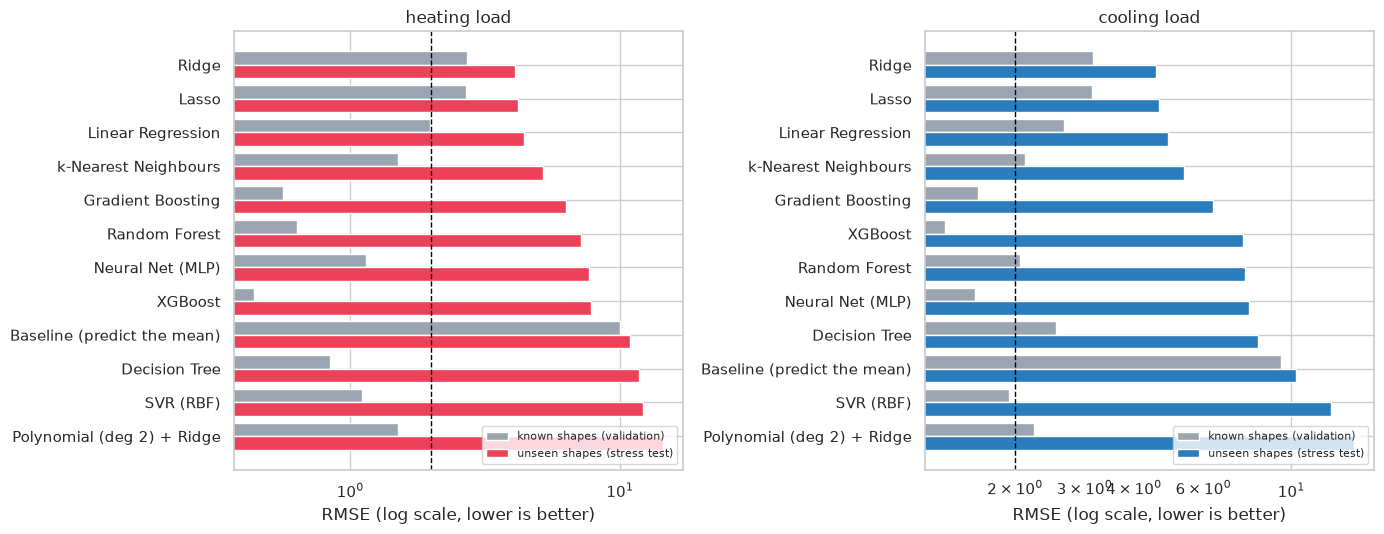

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, t in zip(axes, TARGETS):
    d = cmp_stress[cmp_stress.target == t].sort_values("unseen_shape_RMSE", ascending=False)
    y = np.arange(len(d)); h = 0.4
    ax.barh(y + h/2, d["val_RMSE"], h, color="#9aa5b1", label="known shapes (validation)")
    ax.barh(y - h/2, d["unseen_shape_RMSE"], h, color=COLORS[t], label="unseen shapes (stress test)")
    ax.set_yticks(y); ax.set_yticklabels(d["model"]); ax.set_xscale("log"); ax.axvline(TARGET_RMSE, color="black", ls="--", lw=1)
    ax.set_xlabel("RMSE (log scale, lower is better)"); ax.set_title(t.replace("_", " ")); ax.legend(loc="lower right", fontsize=8)
save("08_unseen_shapes_stress_test")
plt.show()

**How to read this:** the grey bars are what the random validation split measures; the coloured bars are the error when the *entire shape* is hidden from the model. A model that is excellent on the grey bars but poor on the coloured bars has memorised the 12 shapes rather than learned how shape drives energy use.

### The big finding: the ranking flips for unseen shapes
* **Accuracy collapses.** XGBoost's heating error goes from **0.44** on known shapes to **7.80** when the shape is hidden, and its cooling error from 1.33 to 7.54. For comparison, always guessing the average gives about 10.9 and 10.3 on the same test. So for a brand-new shape, even the best flexible models remove only a fraction of the error.
* **The simplest models win the stress test.** Ridge is the best at predicting unseen shapes (RMSE **4.08** for heating with R² 0.84, and **4.55** for cooling with R² 0.77), followed by Linear Regression (4.42 and 4.87). These are the models that were *worst* on known shapes.
* **Polynomial + Ridge explodes.** With default settings it has an RMSE of about 14.4 on unseen shapes for both targets, which is **worse than guessing the average** (10.9 and 10.3). Curves that bend freely extrapolate wildly outside the data.
* **Why:** trees can only repeat values they have already seen, so for a new shape they snap to the nearest known one. Polynomials continue a curve far beyond the data. Straight lines extrapolate gently. With only 12 shapes (and compactness tangled with height) a "new shape" is a big jump.
* **No model meets the targets (RMSE <= 2.0 and R² >= 0.95) on unseen shapes.**

**Consequence for deployment:** model choice depends on the use case. For the 12 known shapes the flexible XGBoost model is far more accurate. For a custom geometry, a simple linear model is the safer fallback, and its error band must be much wider. We will build the app that way in Notebook 3.

---
# Step 6 - Hyperparameter Tuning

Default settings are rarely the best. We search for better ones with the three strategies from the handout, one per model:

| Strategy | How it searches | Pros / cons |
|---|---|---|
| **Grid Search** | Tries **every** combination from a list | Thorough, but explodes with many settings |
| **Random Search** | Tries a fixed number of **random** combinations | Covers a large space cheaply |
| **Bayesian optimisation** (Optuna) | Looks at earlier trials and **chooses the next try where improvement is likely** | Efficient for many settings |

### Cross-validation (CV)
We must not tune using the validation set repeatedly (we would slowly overfit to it). Instead each combination is scored with **5-fold cross-validation on the training set**: split the training data into 5 parts, train on 4 and test on the fifth, rotate, and average the 5 errors. We minimise the **RMSE**. After tuning, the validation set gives one independent check.

| Model | Tuned with | Settings searched |
|---|---|---|
| Polynomial + Ridge | Grid Search | polynomial degree (1, 2, 3) and penalty strength (6 values) = 18 combinations |
| Random Forest | Random Search | trees, depth, leaf size, features per split (30 random combinations) |
| XGBoost | Bayesian optimisation (Optuna) | 8 settings, 40 trials |

> **Note.** This ordinary CV mixes buildings of the same shape across folds, so it shares the "easy case" optimism of the validation split. That is why we add the unseen-shape stress test for the tuned models as well.

In [9]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
tuned, tune_log = {}, []

for t in TARGETS:
    y = ytr[t]
    # ---------- 1) GRID SEARCH: Polynomial + Ridge ----------
    t0 = time.time()
    gpipe = Pipeline([("prep", make_pipe(None).named_steps["prep"]), ("poly", PolynomialFeatures(include_bias=False)), ("model", Ridge())])
    grid = GridSearchCV(gpipe, {"poly__degree": [1, 2, 3], "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100]},
                        cv=cv, scoring="neg_root_mean_squared_error", n_jobs=NJ).fit(Xtr, y)
    tuned[(t, "Polynomial Ridge (Grid)")] = grid.best_estimator_
    tune_log.append({"target": t, "model": "Polynomial Ridge (Grid)", "cv_RMSE": -grid.best_score_, "tries": len(grid.cv_results_["params"]),
                     "params": grid.best_params_, "seconds": time.time() - t0})

    # ---------- 2) RANDOM SEARCH: Random Forest ----------
    t0 = time.time()
    rnd = RandomizedSearchCV(make_pipe(RandomForestRegressor(random_state=SEED, n_jobs=1)),
        {"model__n_estimators": [200, 400, 600], "model__max_depth": [None, 6, 10, 16], "model__min_samples_leaf": [1, 2, 4],
         "model__max_features": [1.0, 0.5, "sqrt"]},
        n_iter=30, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=NJ, random_state=SEED).fit(Xtr, y)
    tuned[(t, "Random Forest (Random)")] = rnd.best_estimator_
    tune_log.append({"target": t, "model": "Random Forest (Random)", "cv_RMSE": -rnd.best_score_, "tries": 30,
                     "params": rnd.best_params_, "seconds": time.time() - t0})

    # ---------- 3) BAYESIAN OPTIMISATION: XGBoost ----------
    t0 = time.time()
    def objective(trial):
        p = dict(n_estimators=trial.suggest_int("n_estimators", 100, 800, step=50),
                 learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
                 max_depth=trial.suggest_int("max_depth", 2, 8), min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
                 subsample=trial.suggest_float("subsample", 0.5, 1.0), colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
                 reg_lambda=trial.suggest_float("reg_lambda", 0.01, 10, log=True), reg_alpha=trial.suggest_float("reg_alpha", 0.001, 1, log=True))
        pipe = make_pipe(XGBRegressor(**p, tree_method="hist", random_state=SEED, n_jobs=1))
        return cross_val_score(pipe, Xtr, y, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=NJ).mean()
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=40)
    best_x = make_pipe(XGBRegressor(**study.best_params, tree_method="hist", random_state=SEED, n_jobs=NJ)).fit(Xtr, y)
    tuned[(t, "XGBoost (Optuna)")] = best_x
    tune_log.append({"target": t, "model": "XGBoost (Optuna)", "cv_RMSE": -study.best_value, "tries": 40,
                     "params": study.best_params, "seconds": time.time() - t0})
    tuned[(t, "_study")] = study
    print("finished tuning:", t)

tl = pd.DataFrame(tune_log)
tl[["target", "model", "cv_RMSE", "tries", "seconds"]].round(3)

finished tuning: heating_load


finished tuning: cooling_load


,target,model,cv_RMSE,tries,seconds
0,heating_load,Polynomial Ridge (Grid),0.648,18,5.765
1,heating_load,Random Forest (Random),0.578,30,17.972
2,heating_load,XGBoost (Optuna),0.413,40,11.833
3,cooling_load,Polynomial Ridge (Grid),1.545,18,2.438
4,cooling_load,Random Forest (Random),1.706,30,20.166
5,cooling_load,XGBoost (Optuna),1.115,40,26.512


In [10]:
for _, r in tl.iterrows():
    print(f"[{r.target}] {r.model}\n    {r.params}\n")

[heating_load] Polynomial Ridge (Grid)
    {'model__alpha': 0.01, 'poly__degree': 3}

[heating_load] Random Forest (Random)
    {'model__n_estimators': 400, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': 10}

[heating_load] XGBoost (Optuna)
    {'n_estimators': 650, 'learning_rate': 0.09486925470008427, 'max_depth': 4, 'min_child_weight': 5, 'subsample': 0.9073428623590826, 'colsample_bytree': 0.6023768740680586, 'reg_lambda': 0.015213275277899027, 'reg_alpha': 0.002389330563034596}

[cooling_load] Polynomial Ridge (Grid)
    {'model__alpha': 0.001, 'poly__degree': 3}

[cooling_load] Random Forest (Random)
    {'model__n_estimators': 400, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 16}

[cooling_load] XGBoost (Optuna)
    {'n_estimators': 800, 'learning_rate': 0.06277539869399044, 'max_depth': 8, 'min_child_weight': 6, 'subsample': 0.8806036840528375, 'colsample_bytree': 0.9420481265360412, 'reg_lambda': 8.712051742054

### Did tuning help? Default vs. tuned on the **validation** set

In [11]:
default_map = {"Polynomial Ridge (Grid)": "Polynomial (deg 2) + Ridge", "Random Forest (Random)": "Random Forest", "XGBoost (Optuna)": "XGBoost"}
cmp_rows = []
for t in TARGETS:
    for tname, dname in default_map.items():
        d = res[(res.target == t) & (res.model == dname)].iloc[0]
        m = evaluate(tuned[(t, tname)], Xva, yva[t])
        cmp_rows.append({"target": t, "model": tname, "default_val_RMSE": d["val_RMSE"], "tuned_val_RMSE": m["RMSE"],
                         "tuned_val_MAE": m["MAE"], "tuned_val_R2": m["R2"],
                         "tuned_train_RMSE": evaluate(tuned[(t, tname)], Xtr, ytr[t])["RMSE"]})
cmp = pd.DataFrame(cmp_rows)
cmp["change_RMSE"] = cmp["tuned_val_RMSE"] - cmp["default_val_RMSE"]
cmp.round(3)

,target,model,default_val_RMSE,tuned_val_RMSE,tuned_val_MAE,tuned_val_R2,tuned_train_RMSE,change_RMSE
0,heating_load,Polynomial Ridge (Grid),1.511,0.520,0.367,0.997,0.231,-0.991
1,heating_load,Random Forest (Random),0.638,0.588,0.386,0.997,0.235,-0.049
2,heating_load,XGBoost (Optuna),0.441,0.414,0.269,0.998,0.148,-0.027
3,cooling_load,Polynomial Ridge (Grid),2.235,1.477,0.962,0.975,0.422,-0.758
4,cooling_load,Random Forest (Random),2.052,1.832,1.148,0.962,0.636,-0.220
5,cooling_load,XGBoost (Optuna),1.330,1.081,0.692,0.987,0.185,-0.249


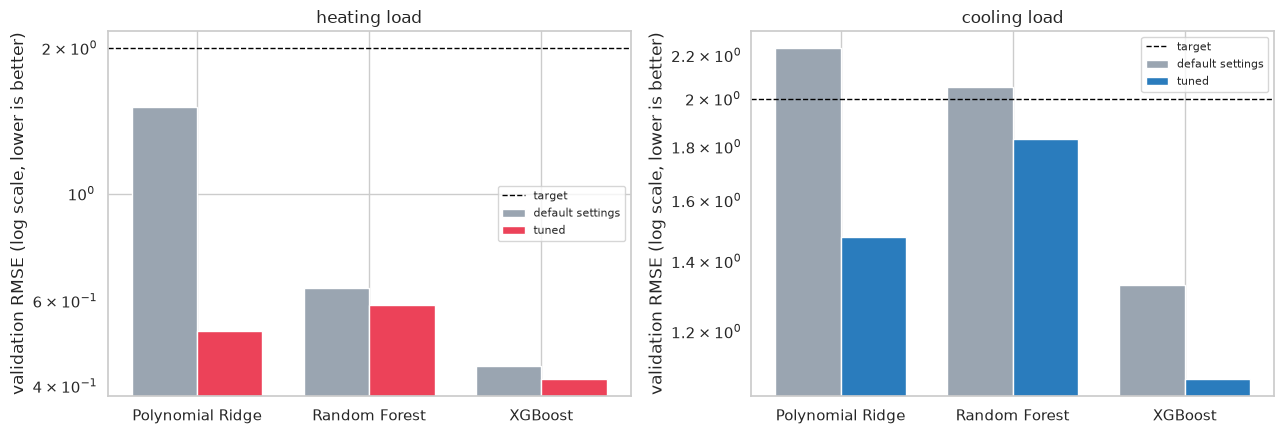

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, t in zip(axes, TARGETS):
    d = cmp[cmp.target == t]; x = np.arange(len(d)); w = 0.38
    ax.bar(x - w/2, d["default_val_RMSE"], w, label="default settings", color="#9aa5b1")
    ax.bar(x + w/2, d["tuned_val_RMSE"], w, label="tuned", color=COLORS[t])
    ax.set_xticks(x); ax.set_xticklabels([m.split(" (")[0] for m in d["model"]])
    ax.axhline(TARGET_RMSE, color="black", ls="--", lw=1, label="target"); ax.set_yscale("log")
    ax.set_ylabel("validation RMSE (log scale, lower is better)"); ax.set_title(t.replace("_", " ")); ax.legend(fontsize=8)
save("09_tuning_before_after")
plt.show()

### What tuning did
* **Polynomial + Ridge improved the most** (heating RMSE 1.51 to 0.52, cooling 2.24 to 1.48): the search chose a degree-3 polynomial with a very light penalty.
* **XGBoost improved modestly but stayed the best:** heating 0.441 to **0.414** and cooling 1.330 to **1.081**. Random Forest improved slightly (0.638 to 0.588 and 2.052 to 1.832).
* The cross-validation RMSE of the tuned XGBoost (0.413 and 1.115) agrees closely with its validation RMSE (0.414 and 1.081), so there is no sign that we overfitted the validation set while tuning.
* **A warning from the stress test (table above):** the tuned degree-3 polynomial is excellent on known shapes but terrible on unseen ones (RMSE 29.4 for heating and 59.0 for cooling). Tuned XGBoost scores 5.28 and 7.28 on unseen shapes, and tuned Random Forest 6.23 and 5.75. A model that wins on validation can still be the wrong choice for a different use.

### How Bayesian optimisation behaved
Each dot is one Optuna trial (one setting combination); the line is the best score found so far (lower RMSE is better).

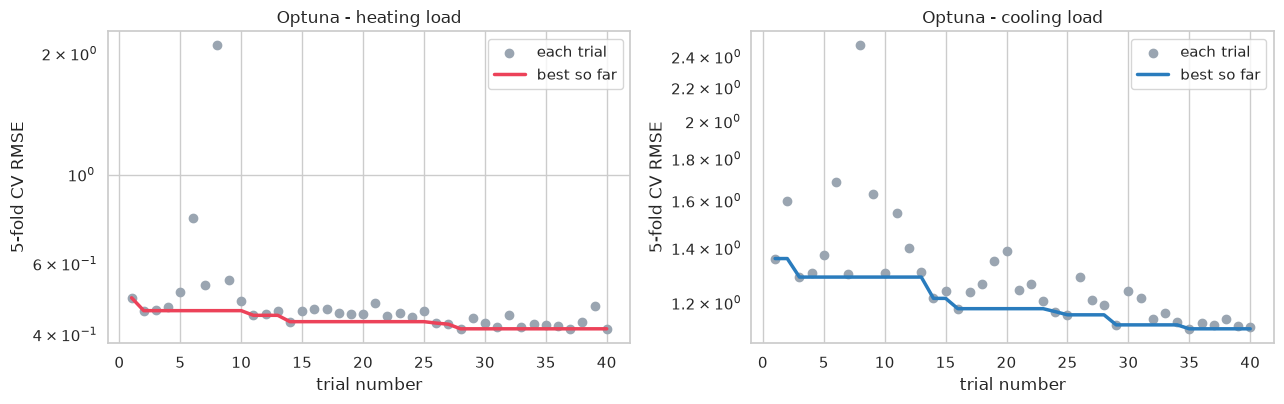

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, t in zip(axes, TARGETS):
    vals = [-tr.value for tr in tuned[(t, "_study")].trials]
    ax.scatter(range(1, len(vals) + 1), vals, color="#9aa5b1", label="each trial")
    ax.plot(range(1, len(vals) + 1), np.minimum.accumulate(vals), color=COLORS[t], lw=2.5, label="best so far")
    ax.set_yscale("log"); ax.set_title(f"Optuna - {t.replace('_', ' ')}"); ax.set_xlabel("trial number"); ax.set_ylabel("5-fold CV RMSE"); ax.legend()
save("10_optuna_history")
plt.show()

### The unseen-shape stress test for the tuned models

In [14]:
stress_t = []
for t in TARGETS:
    for tname in default_map:
        est = tuned[(t, tname)]
        # re-create the tuned model (same settings, untrained) for every left-out shape
        oof = np.zeros(len(tv))
        for tr_i, te_i in LeaveOneGroupOut().split(Xtv, ytv[t], gtv):
            pipe = clone(est).fit(Xtv.iloc[tr_i], ytv[t].iloc[tr_i]); oof[te_i] = pipe.predict(Xtv.iloc[te_i])
        oof_store[(t, tname)] = oof
        stress_t.append({"target": t, "model": tname, "unseen_shape_RMSE": rmse(ytv[t], oof), "unseen_shape_R2": r2_score(ytv[t], oof)})
stress_t = pd.DataFrame(stress_t)
cmp = cmp.merge(stress_t, on=["target", "model"])
cmp[["target", "model", "tuned_val_RMSE", "tuned_val_R2", "unseen_shape_RMSE", "unseen_shape_R2"]].round(3)

,target,model,tuned_val_RMSE,tuned_val_R2,unseen_shape_RMSE,unseen_shape_R2
0,heating_load,Polynomial Ridge (Grid),0.520,0.997,29.407,-7.506
1,heating_load,Random Forest (Random),0.588,0.997,6.230,0.618
2,heating_load,XGBoost (Optuna),0.414,0.998,5.276,0.726
3,cooling_load,Polynomial Ridge (Grid),1.477,0.975,59.022,-37.636
4,cooling_load,Random Forest (Random),1.832,0.962,5.753,0.633
5,cooling_load,XGBoost (Optuna),1.081,0.987,7.284,0.412


---
## 6.x Choosing the best model for each target
We pick, for each target, the tuned model with the lowest **validation RMSE** (the primary criterion, because it matches the "known shape" use case), and then examine it closely. The unseen-shape column above tells us how far to trust it for brand-new shapes.

In [15]:
best = {}
for t in TARGETS:
    c = cmp[cmp.target == t].sort_values("tuned_val_RMSE")
    best[t] = c.iloc[0]["model"]
    print(f"{t:>13}: best model = {best[t]:<26} validation RMSE = {c.iloc[0]['tuned_val_RMSE']:.3f}, R2 = {c.iloc[0]['tuned_val_R2']:.4f}"
          f" | unseen-shape RMSE = {c.iloc[0]['unseen_shape_RMSE']:.2f}")

 heating_load: best model = XGBoost (Optuna)           validation RMSE = 0.414, R2 = 0.9983 | unseen-shape RMSE = 5.28
 cooling_load: best model = XGBoost (Optuna)           validation RMSE = 1.081, R2 = 0.9868 | unseen-shape RMSE = 7.28


### Predicted vs. actual
Every dot is one validation building. A perfect model puts all dots on the dashed diagonal.

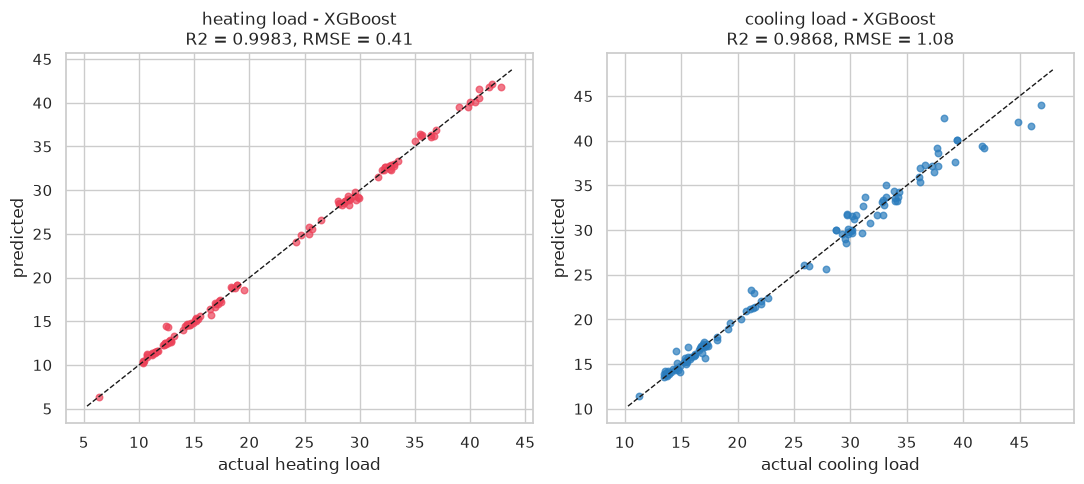

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, t in zip(axes, TARGETS):
    pred = tuned[(t, best[t])].predict(Xva); act = yva[t].values
    ax.scatter(act, pred, s=22, color=COLORS[t], alpha=0.7)
    lim = [min(act.min(), pred.min()) - 1, max(act.max(), pred.max()) + 1]; ax.plot(lim, lim, "k--", lw=1)
    ax.set_xlabel(f"actual {t.replace('_', ' ')}"); ax.set_ylabel("predicted")
    ax.set_title(f"{t.replace('_', ' ')} - {best[t].split(' (')[0]}\nR2 = {r2_score(act, pred):.4f}, RMSE = {rmse(act, pred):.2f}")
save("11_predicted_vs_actual")
plt.show()

### Residuals: where are the mistakes?
A **residual** is *actual - predicted*. A healthy model has residuals that are **small, centred on zero and without a pattern**. A pattern (for example, errors that grow for large loads) means the model is missing something.

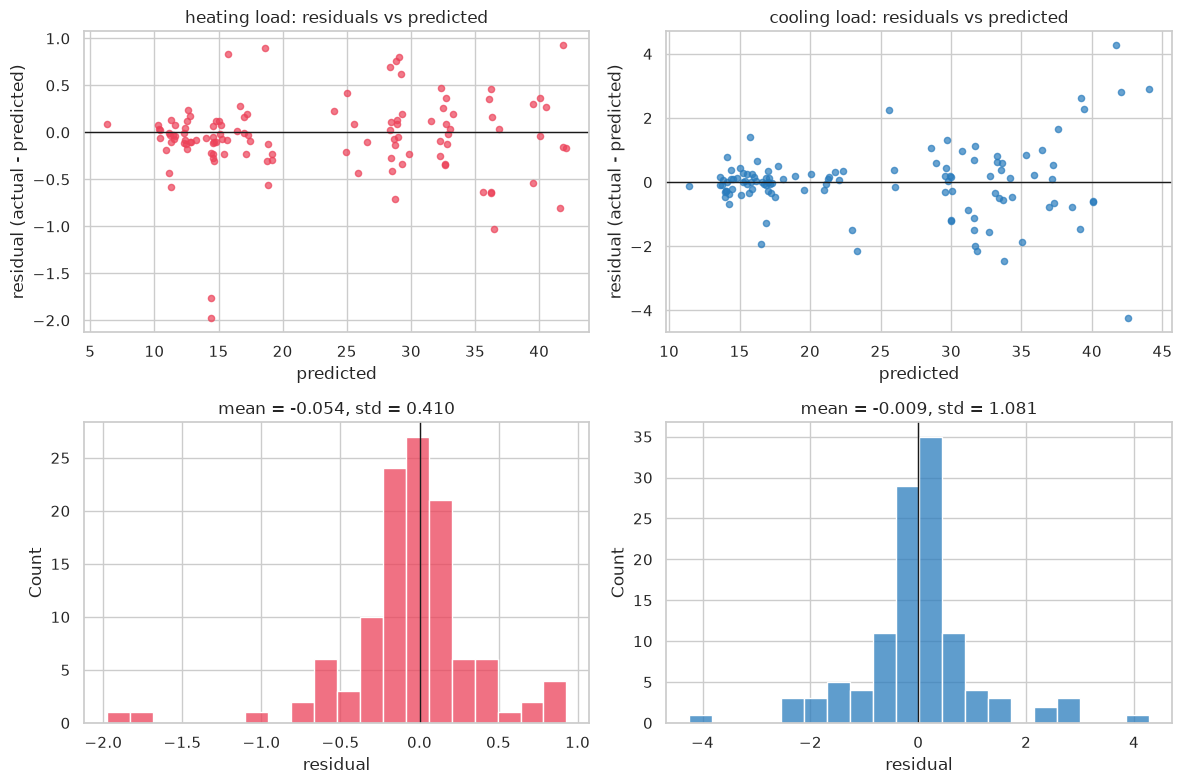

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for j, t in enumerate(TARGETS):
    pred = tuned[(t, best[t])].predict(Xva); resid = yva[t].values - pred
    axes[0, j].scatter(pred, resid, s=20, color=COLORS[t], alpha=0.7); axes[0, j].axhline(0, color="k", lw=1)
    axes[0, j].set_xlabel("predicted"); axes[0, j].set_ylabel("residual (actual - predicted)"); axes[0, j].set_title(f"{t.replace('_', ' ')}: residuals vs predicted")
    sns.histplot(resid, bins=20, color=COLORS[t], ax=axes[1, j]); axes[1, j].axvline(0, color="k", lw=1)
    axes[1, j].set_xlabel("residual"); axes[1, j].set_title(f"mean = {resid.mean():.3f}, std = {resid.std():.3f}")
save("12_residuals")
plt.show()

**Reading the residuals.** The residuals are centred on zero (mean -0.05 for heating and -0.01 for cooling) with a standard deviation of 0.41 and 1.08. For **heating** they show no clear pattern. For **cooling** the scatter **grows for high loads**: above a predicted load of about 30 the errors reach about 4, while for low loads they stay below about 1. So the model is least certain for the hottest-running buildings. This is why a single error band is only an average: errors are larger for high loads.

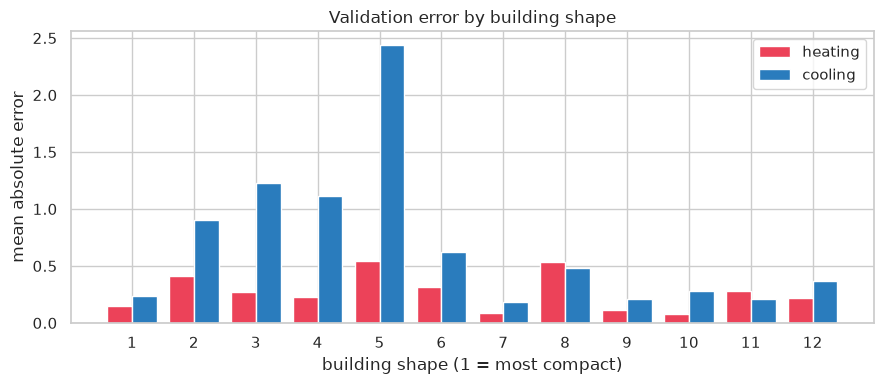

shape_id,1,2,3,4,5,6,7,8,9,10,11,12
heating MAE,0.152,0.410,0.271,0.228,0.541,0.317,0.088,0.539,0.115,0.083,0.280,0.219
cooling MAE,0.235,0.904,1.232,1.117,2.437,0.626,0.183,0.480,0.214,0.283,0.211,0.366


In [18]:
# Where does the error concentrate? Mean absolute error for each building shape (validation buildings)
vv = val.copy()
for t in TARGETS: vv[f"err_{t}"] = (yva[t].values - tuned[(t, best[t])].predict(Xva)).__abs__()
by_shape = vv.groupby("shape_id")[[f"err_{t}" for t in TARGETS]].mean().round(3)
by_shape.columns = ["heating MAE", "cooling MAE"]
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(by_shape)); w = 0.4
ax.bar(x - w/2, by_shape["heating MAE"], w, color=HEAT, label="heating"); ax.bar(x + w/2, by_shape["cooling MAE"], w, color=COOL, label="cooling")
ax.set_xticks(x); ax.set_xticklabels(by_shape.index); ax.set_xlabel("building shape (1 = most compact)"); ax.set_ylabel("mean absolute error")
ax.set_title("Validation error by building shape"); ax.legend()
save("13_error_by_shape")
plt.show()
by_shape.T

### Which inputs drive the predictions? (permutation importance)
**Permutation importance** shuffles one input at a time and measures how much the validation RMSE gets **worse**. A big increase means the model relies heavily on that input. (Remember from Notebook 1 that compactness and height are tangled, and several inputs overlap, so importance can be shared among them.)

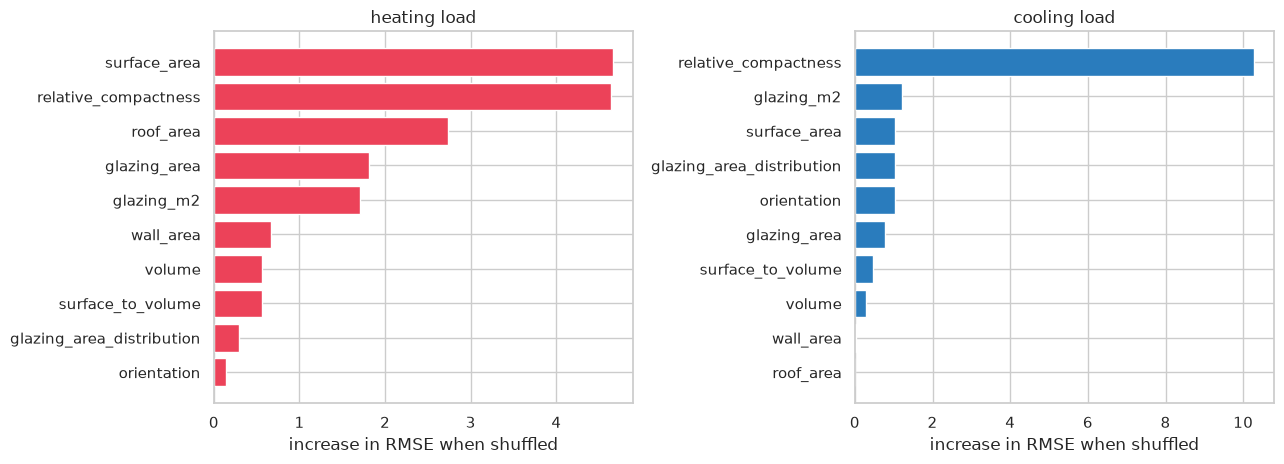

,heating_load,cooling_load
glazing_area,1.82,0.78
glazing_area_distribution,0.29,1.04
glazing_m2,1.71,1.22
orientation,0.14,1.03
overall_height,0.13,0.00
relative_compactness,4.63,10.28
roof_area,2.73,0.02
surface_area,4.66,1.04


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); imp_tables = {}
for ax, t in zip(axes, TARGETS):
    pi = permutation_importance(tuned[(t, best[t])], Xva, yva[t], scoring="neg_root_mean_squared_error", n_repeats=10, random_state=SEED, n_jobs=NJ)
    imp = pd.Series(pi.importances_mean, index=FEATS).sort_values(ascending=False); imp_tables[t] = imp
    top = imp.head(10)[::-1]
    ax.barh(top.index, top.values, color=COLORS[t]); ax.set_xlabel("increase in RMSE when shuffled"); ax.set_title(t.replace("_", " "))
save("14_permutation_importance")
plt.show()
pd.DataFrame(imp_tables).round(2).head(8)

**Be careful reading this chart.** The model relies mostly on `relative_compactness` (importance 4.6 for heating and 10.3 for cooling) and the areas, and gives `overall_height` almost no importance (0.13 and 0.00). That does **not** mean height is unimportant: in Notebook 1 it was the strongest effect (average heating 31.3 against 13.3). Compactness and the areas **identify the building shape**, and the shape already tells the model the height. Once the model knows compactness, height adds nothing, so shuffling height changes little. When inputs are tangled like this, an importance score says *which column the model happened to use*, not *which factor matters most in the real world*.

### How does the predicted load change when we vary one input? (partial dependence)
A **partial dependence plot** shows the model's average prediction as one input moves while everything else stays as in the data. It tells us what the model has learned about that input.

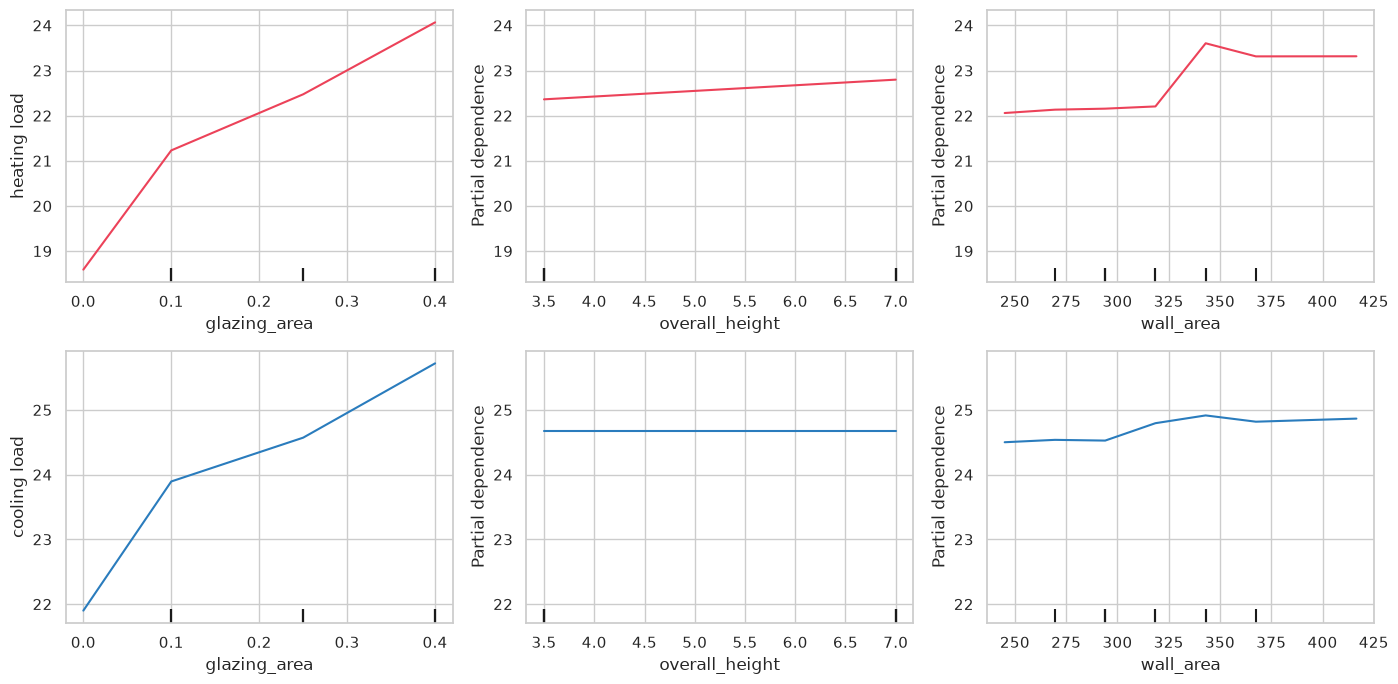

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for j, t in enumerate(TARGETS):
    PartialDependenceDisplay.from_estimator(tuned[(t, best[t])], Xva, ["glazing_area", "overall_height", "wall_area"],
                                            ax=axes[j], line_kw={"color": COLORS[t]})
    axes[j][0].set_ylabel(t.replace("_", " "))
save("15_partial_dependence")
plt.show()

**What the partial dependence plots say.** Only the **glazing area** curve is clean and believable: more windows raise the average prediction from about 18.6 to 24.1 for heating and from 21.9 to 25.7 for cooling, which agrees with Notebook 1. The **height** curve is almost flat for the same reason as above: changing height while holding compactness and the areas fixed creates impossible buildings the model never saw, so the plot does not describe a real design change. The partial dependence plot therefore only works well for inputs that can change **independently**, such as the windows.

### A realistic error margin for every prediction
A single predicted number is not enough: an architect wants to know **how far off it could be**. We use the model's *out-of-sample* errors: predict every training building with 5-fold cross-validation (each building predicted by a model that did not see it), and take the size of error that 90% of those predictions stay within. We then **check on the validation set** that roughly 90% of buildings really do fall inside the band.

In [21]:
interval, cover_rows = {}, []
for t in TARGETS:
    oof = cross_val_predict(clone(tuned[(t, best[t])]), Xtr, ytr[t], cv=cv, n_jobs=NJ)
    q90 = float(np.quantile(np.abs(ytr[t].values - oof), 0.90)); interval[t] = q90
    pred = tuned[(t, best[t])].predict(Xva)
    cover_rows.append({"target": t, "90% error band (+/-)": q90, "share of validation buildings inside the band": float((np.abs(yva[t].values - pred) <= q90).mean())})
pd.DataFrame(cover_rows).round(3)

,target,90% error band (+/-),share of validation buildings inside the band
0,heating_load,0.659,0.904
1,cooling_load,1.774,0.887


**The bands are well calibrated:** 90.4% of the validation buildings fall inside the heating band (+/- 0.66) and 88.7% inside the cooling band (+/- 1.77), close to the intended 90%. These bands only apply to **known shapes**.

---
## Final validation scorecard
Compared with the success criteria from Notebook 1: **R² >= 0.95** and **RMSE <= 2.0** for both targets.

In [22]:
score = []
for t in TARGETS:
    m = evaluate(tuned[(t, best[t])], Xva, yva[t])
    u = cmp[(cmp.target == t) & (cmp.model == best[t])].iloc[0]
    score.append({"target": t, "model": best[t], "MAE": m["MAE"], "RMSE": m["RMSE"], "R2": m["R2"],
                  "unseen-shape RMSE": u["unseen_shape_RMSE"], "unseen-shape R2": u["unseen_shape_R2"]})
score = pd.DataFrame(score)
score["meets R2 target"] = score["R2"] >= TARGET_R2
score["meets RMSE target"] = score["RMSE"] <= TARGET_RMSE
score["unseen shapes meet targets"] = (score["unseen-shape R2"] >= TARGET_R2) & (score["unseen-shape RMSE"] <= TARGET_RMSE)
score.round(3)

,target,model,MAE,RMSE,R2,unseen-shape RMSE,unseen-shape R2,meets R2 target,meets RMSE target,unseen shapes meet targets
0,heating_load,XGBoost (Optuna),0.269,0.414,0.998,5.276,0.726,True,True,False
1,cooling_load,XGBoost (Optuna),0.692,1.081,0.987,7.284,0.412,True,True,False


### Conclusions of Notebook 2
| | Heating load | Cooling load |
|---|---|---|
| Best model (validation) | XGBoost, Bayesian-tuned | XGBoost, Bayesian-tuned |
| Known shapes: RMSE (target <= 2.0) | **0.414** (met) | **1.081** (met) |
| Known shapes: R² (target >= 0.95) | **0.998** (met) | **0.987** (met) |
| 90% error band | +/- 0.66 | +/- 1.77 |
| **Unseen shapes**: RMSE / R² | 5.28 / 0.73 (not met) | 7.28 / 0.41 (not met) |

1. **Both targets meet the success criteria for the 12 known shapes**, by a wide margin.
2. **They do not meet them for unseen shapes**, and the best model there is a simple linear one. A model's validation score only describes the situation the validation data represents.
3. **Tuning helped, but the algorithm family mattered much more** than the settings: boosted trees against straight lines.
4. Interpretation tools (importance, partial dependence) must be read with care here, because compactness, height and the areas are tangled.

**Next (Notebook 3):** the final test, a final unseen-shape test on all 12 shapes, and the deployment bundle, with a **simple linear fallback model for custom geometries**.

### Saving results for Notebook 3
We save, for each target, the **unfitted** best pipeline (so Notebook 3 can retrain it on train + validation), the fitted one, the 90% error band, and the comparison tables.

In [23]:
config = {}
for t in TARGETS:
    name = best[t]; pipe = tuned[(t, name)]
    joblib.dump(pipe, MODELS / f"{t}_fitted_on_train.joblib")
    joblib.dump(clone(pipe), MODELS / f"{t}_unfitted.joblib")
    row = tl[(tl.target == t) & (tl.model == name)].iloc[0]
    config[t] = {"model": name, "features": FEATS, "error_band_90": interval[t],
                 "best_params": {k: (v.item() if hasattr(v, "item") else v) for k, v in row.params.items()}, "cv_RMSE": float(row.cv_RMSE)}
json.dump(config, open(MODELS / "config.json", "w"), indent=2, default=str)
res.to_csv(MODELS / "model_comparison_default.csv", index=False)
cmp.to_csv(MODELS / "tuning_comparison.csv", index=False)
stress.to_csv(MODELS / "unseen_shape_default.csv", index=False)
print("Saved:", sorted(p.name for p in MODELS.iterdir()))

Saved: ['config.json', 'cooling_load_fitted_on_train.joblib', 'cooling_load_unfitted.joblib', 'heating_load_fitted_on_train.joblib', 'heating_load_unfitted.joblib', 'model_comparison_default.csv', 'tuning_comparison.csv', 'unseen_shape_default.csv']


---
# Glossary (new terms in this notebook)
* **Baseline:** the simplest possible predictor; every real model must beat it.
* **Regularisation (Ridge / Lasso):** a penalty on large weights that keeps a model stable and simple.
* **Polynomial features:** extra columns made of squares and products of the inputs, letting a linear model bend.
* **Hyperparameter / parameter:** a setting chosen before training / a number the model learns itself.
* **Cross-validation:** repeatedly training on part of the training data and testing on the rest.
* **Underfitting / overfitting:** too simple to learn the pattern / so complex it memorises noise.
* **Learning curve:** error as a function of the amount of training data.
* **Extrapolation:** predicting outside the range of the training data (trees cannot do this; they repeat the closest values they know).
* **Leave-one-shape-out:** a test where a whole building shape is hidden from training and then predicted.
* **Residual:** actual value minus predicted value.
* **Permutation importance:** how much the error grows when one input's values are shuffled.
* **Partial dependence:** the model's average prediction as one input varies.